In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [46]:
def fixed_boundary(t,a):
    """Constant boundary at value a."""
    return np.full_like(t, a)


def linear_collapse(t,a,k,epsilon):
    """
    Linearly collapsing boundary.
    B(t) = max(a - k*t, epsilon)
    """
    return np.maximum(a - k * t, epsilon)


def exponential_collapse(t, a, lam, epsilon=1e-4):
    """
    Exponentially collapsing boundary.
    B(t) = a * exp(-lambda * t)
    
    Parameters
    ----------
    lam : float
        Decay rate (lambda). Larger = faster collapse.
    """
    return np.maximum(a * np.exp(-lam * t), epsilon)


def sigmoid_collapse( t , a, k_sig, t_mid) :
    """
    Sigmoid (logistic) collapsing boundary.
    B(t) = a * (1 - sigmoid(k * (t - t_mid)))
    
    Parameters
    ----------
    k_sig  : float  Steepness of collapse (larger = sharper)
    t_mid  : float  Time of inflection point
    """
    sig = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (1.0 - sig), 1e-4)


In [48]:



def sample_prior_exponential_boundary(n_samples: int, rng=None) -> np.ndarray:
    """
    Prior for DDM with exponential collapsing boundary.
    
    Parameters (5D):
    ----------------
    v    ~ Normal(0, 2)       drift rate
    a    ~ HalfNormal(1.0)    boundary separation (must be > 0)
    t0   ~ Uniform(0.05, 0.5) non-decision time
    z    ~ Uniform(0.3, 0.7)  starting point (near 0.5 = unbiased)
    lam  ~ HalfNormal(0.5)    exponential decay rate (must be > 0)
    
    Returns
    -------
    samples : shape (n_samples, 5)
    """
    if rng is None:
        rng = np.random.default_rng()
    
    v   = rng.normal(0, 2, n_samples)
    a   = np.abs(rng.normal(0, 1.0, n_samples)) + 0.1       # HalfNormal + offset
    t0  = rng.uniform(0.05, 0.5, n_samples)
    z   = rng.uniform(0.3, 0.7, n_samples)
    lam = np.abs(rng.normal(0, 0.5, n_samples)) + 0.01      # decay rate > 0
    
    return np.stack([v, a, t0, z, lam], axis=-1)


def sample_prior_sigmoid_boundary(n_samples: int, rng=None) -> np.ndarray:
    """
    Prior for DDM with sigmoid collapsing boundary.
    
    Parameters (6D):
    ----------------
    v      ~ Normal(0, 2)
    a      ~ HalfNormal(1.0)
    t0     ~ Uniform(0.05, 0.5)
    z      ~ Uniform(0.3, 0.7)
    k_sig  ~ HalfNormal(5.0)    collapse steepness
    t_mid  ~ Uniform(0.3, 1.5)  inflection point
    """
    if rng is None:
        rng = np.random.default_rng()
    
    v     = rng.normal(0, 2, n_samples)
    a     = np.abs(rng.normal(0, 1.0, n_samples)) + 0.1
    t0    = rng.uniform(0.05, 0.5, n_samples)
    z     = rng.uniform(0.3, 0.7, n_samples)
    k_sig = np.abs(rng.normal(0, 5.0, n_samples)) + 0.5
    t_mid = rng.uniform(0.3, 1.5, n_samples)
    
    return np.stack([v, a, t0, z, k_sig, t_mid], axis=-1)




In [ ]:
def simulate_ddm_trials(
    v: float,
    a: float,
    t0: float,
    z: float,                         # starting point bias, in [0,1]; 0.5 = unbiased
    boundary_fn,
    boundary_params: dict,
    n_trials: int = 200,
    dt: float = 0.001,
    max_time: float = 3.0,
    deadline=None, # if set, truncate at deadline
    noise_sd: float = 1.0,
    rng=None,
) :
    """
    Simulate DDM via Euler-Maruyama integration.
    
    
    Returns
    -------
    rts     : shape (n_trials,)  RT in seconds; np.nan = non-response
    choices : shape (n_trials,)  1=correct (upper), 0=error (lower), -1=non-response
    """
    if rng is None:
        rng = np.random.default_rng()
    
    rts = np.full(n_trials, np.nan)
    choices = np.full(n_trials, -1, dtype=int)
    
    max_steps = int(max_time / dt)
    time_axis = np.arange(max_steps) * dt
    
    # Pre-compute boundary values at each time step
    boundary = boundary_fn(time_axis, a=a, **boundary_params)
    
    for i in range(n_trials):
        # Starting point: z is relative [0,1]; convert to absolute position
        x = (z - 0.5) * 2 * a   # maps z=0.5 → 0, z=0 → -a, z=1 → +a
      
        
        for step in range(max_steps):
            t_current = step * dt
            
            # Check deadline
            if deadline is not None and t_current >= deadline:
                # Non-response
                break
            
            b = boundary[step]
            
            # Check boundaries
            if x >= b:
                rts[i] = t0 + t_current
                choices[i] = 1  # correct
               
                break
            elif x <= -b:
                rts[i] = t0 + t_current
                choices[i] = 0  # error
                
                break
            
            # Euler-Maruyama update
            x += v * dt + noise_sd * np.sqrt(dt) * rng.standard_normal()
    
    return rts, choices


In [ ]:
def prior_fn(batch_size):
    """Returns dict with 'prior_draws' key: shape (batch_size, n_params)."""
    samples = sample_prior_exponential_boundary(batch_size)
    return {"prior_draws": samples}


# Simulator function for sbi
def simulator_fn(prior_draws: np.ndarray,
                 boundary_type: str = 'exponential',
                 n_trials: int = 200,
                 deadline: float = 2.0) -> dict:
    """
    boundary_type : 'exponential' or 'sigmoid'
    """
    boundary_fn = exponential_collapse if boundary_type == 'exponential' else sigmoid_collapse
    batch_size = prior_draws.shape[0]
    rng = np.random.default_rng()

    all_data = []
    for i in range(batch_size):
        if boundary_type == 'exponential':
            v, a, t0, z, lam = prior_draws[i]
            boundary_params = {'lam': lam}
        else:  # sigmoid
            v, a, t0, z, k_sig, t_mid = prior_draws[i]
            boundary_params = {'k_sig': k_sig, 't_mid': t_mid}

        rts, choices = simulate_ddm_trials(
            v=v, a=a, t0=t0, z=z,
            boundary_fn=boundary_fn,
            boundary_params=boundary_params,
            n_trials=n_trials,
            dt=0.001,
            max_time=deadline + 0.5,
            deadline=deadline,
            rng=rng,
        )
        rts_clean = np.where(np.isnan(rts), 0.0, rts)
        trial_data = np.stack([rts_clean, choices.astype(float)], axis=-1)
        all_data.append(trial_data)

    return {"sim_data": np.array(all_data)}

In [50]:
rts_exp, choices_exp = simulate_ddm_trials(
    v=1.0, a=1.0, t0=0.2, z=0.5,
    boundary_fn=exponential_collapse,
    boundary_params={'lam': 0.3},
    n_trials=500, dt=0.001, max_time=3.0, deadline=2.0,
)
df_exp = pd.DataFrame({'rt': rts_exp, 'choice': choices_exp})
df_exp.to_csv('../data/simulated_data_exponential.csv', index=False)

rts_sig, choices_sig = simulate_ddm_trials(
    v=1.0, a=1.0, t0=0.2, z=0.5,
    boundary_fn=sigmoid_collapse,
    boundary_params={'k_sig': 5.0, 't_mid': 0.8},
    n_trials=500, dt=0.001, max_time=3.0, deadline=2.0,
)
df_sig = pd.DataFrame({'rt': rts_sig, 'choice': choices_sig})
df_sig.to_csv('../data/simulated_data_sigmoid.csv', index=False)

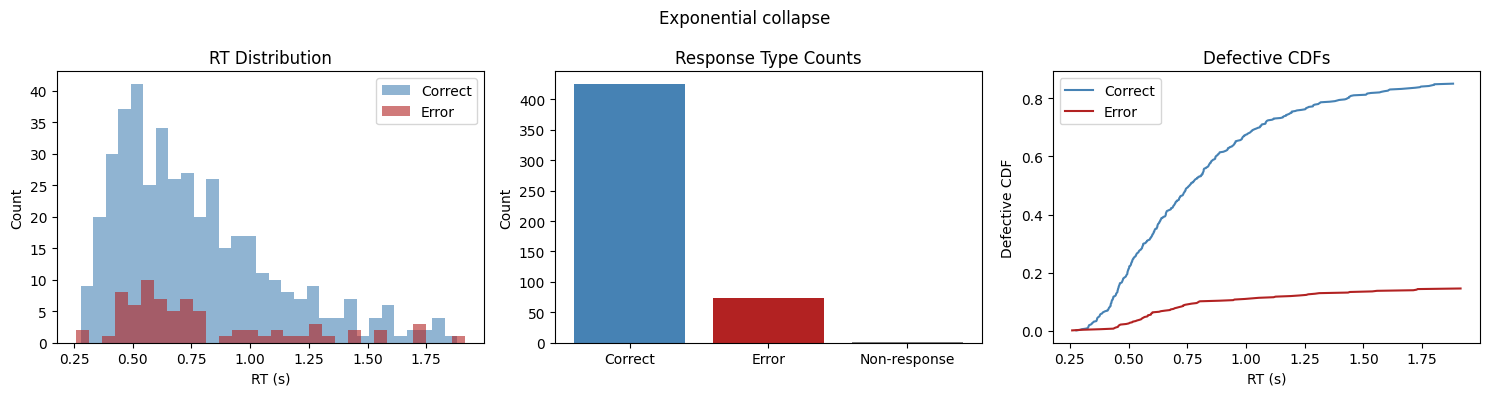

[Exponential collapse] Non-response rate: 0.40%
[Exponential collapse] Accuracy (of responses): 85.34%


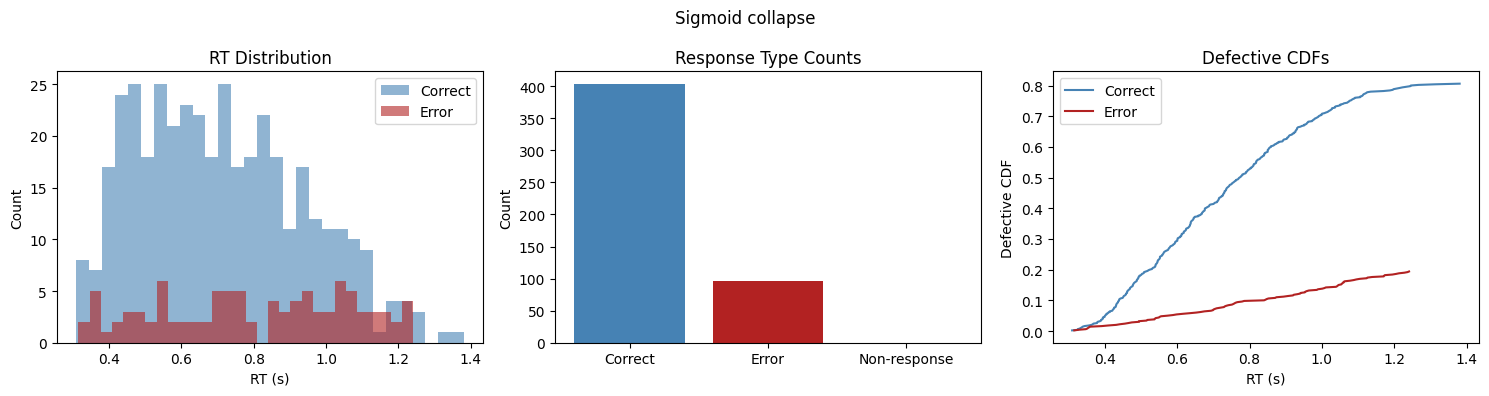

[Sigmoid collapse] Non-response rate: 0.00%
[Sigmoid collapse] Accuracy (of responses): 80.60%


In [51]:
def plot_ddm_results(df, title_prefix=""):
    correct_rts = df.loc[df['choice'] == 1, 'rt'].dropna()
    error_rts   = df.loc[df['choice'] == 0, 'rt'].dropna()
    n_nonresp   = (df['choice'] == -1).sum()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(title_prefix)

    axes[0].hist(correct_rts, bins=30, alpha=0.6, label='Correct', color='steelblue')
    axes[0].hist(error_rts, bins=30, alpha=0.6, label='Error', color='firebrick')
    axes[0].set_xlabel('RT (s)'); axes[0].set_ylabel('Count')
    axes[0].set_title('RT Distribution'); axes[0].legend()

    counts = df['choice'].value_counts().reindex([1, 0, -1], fill_value=0)
    axes[1].bar(['Correct', 'Error', 'Non-response'], counts.values,
                color=['steelblue', 'firebrick', 'gray'])
    axes[1].set_ylabel('Count'); axes[1].set_title('Response Type Counts')

    p_correct = len(correct_rts) / len(df)
    p_error = len(error_rts) / len(df)

    x_c = np.sort(correct_rts); y_c = np.arange(1, len(x_c)+1) / len(x_c) * p_correct
    x_e = np.sort(error_rts);   y_e = np.arange(1, len(x_e)+1) / len(x_e) * p_error

    axes[2].plot(x_c, y_c, color='steelblue', label='Correct')
    axes[2].plot(x_e, y_e, color='firebrick', label='Error')
    axes[2].set_xlabel('RT (s)'); axes[2].set_ylabel('Defective CDF')
    axes[2].set_title('Defective CDFs'); axes[2].legend()

    plt.tight_layout()
    plt.show()

    print(f"[{title_prefix}] Non-response rate: {n_nonresp/len(df):.2%}")
    print(f"[{title_prefix}] Accuracy (of responses): {p_correct/(p_correct+p_error):.2%}")


plot_ddm_results(pd.read_csv('../data/simulated_data_exponential.csv'), "Exponential collapse")
plot_ddm_results(pd.read_csv('../data/simulated_data_sigmoid.csv'), "Sigmoid collapse")